# 0. Summary of Imaging Analyses Results

__This notebook also merge all the imaging analyses results together and output.__

In [40]:
# imports
import os
import polars as pl
import pandas as pd
import pandas as pd
import numpy as np
from tqdm import tqdm
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import umap
from functools import reduce
import operator
from adjustText import adjust_text

In [41]:
BATCH_LIST_DICT = {
    "2024_01_23_Batch_7": "2024_02_Batch_7-8", 
    "2024_02_06_Batch_8": "2024_02_Batch_7-8",
    "2024_12_09_Batch_11": "2024_12_Batch_11-12", 
    "2024_12_09_Batch_12": "2024_12_Batch_11-12",
    "2025_01_27_Batch_13": "2025_01_Batch_13-14", 
    "2025_01_28_Batch_14": "2025_01_Batch_13-14",
    "2025_03_17_Batch_15": "2025_03_Batch_15-16", 
    "2025_03_17_Batch_16": "2025_03_Batch_15-16"
}

BIO_REP_BATCHES_DICT = {
    "2024_01_Batch_7-8": ("2024_01_23_Batch_7", "2024_02_06_Batch_8"),
    "2024_12_Batch_11-12": ("2024_12_09_Batch_11", "2024_12_09_Batch_12"),
    "2025_03_Batch_15-16": ("2025_03_17_Batch_15", "2025_03_17_Batch_16"),
    # "2025_01_Batch_13-14": ("2025_01_27_Batch_13", "2025_01_28_Batch_14")
}

METADATA_INPUT = "../../../../1_allele_collection/3_outputs"
FEAT_SETS = ["DNA", "Mito", "GFP", "AGP", "Morph"]
PLATEMAP_DIR = "../../2_analysis/1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/inputs/metadata/platemaps/{batch_id}/platemap"
CLASS_RES_DIR = "../../2_analysis/1_snakemake_pipeline/2025_varchamp_snakemake/2.snakemake_pipeline/outputs/classification_analyses"
IMG_QC_DIR = "../../3_outputs/1_snakemake_pipeline/2.smp_results_analyses/1.image_qc_outputs/{bio_rep}"
CLASS_RES_OUTDIR = "../../3_outputs/1_snakemake_pipeline/2.smp_results_analyses/3.classification_results"

# integrative_inputs = "../../../../3_integrated_assay_results/1_inputs"

## 1. Loading Data

### 1.1 Metadata

In [43]:
clin_var_df = pl.read_csv(f"{METADATA_INPUT}/varchamp_consolidated_alleles_clinvar_gnomad_sequence_confirmed.tsv", 
                          separator="\t", infer_schema_length=10000
).with_columns(
    pl.concat_str([pl.col("symbol"),pl.col("aa_change")], separator="_").alias("gene_allele")
)
clin_var_df.head()

symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,entry_plate_orig,entry_well_orig,entry_plate_conso,entry_well_conso,entry_seq_pool,db_plate,db_well,n2h_plate,n2h_well,dualip_plate,dualip_well,mislocalization_plate,mislocalization_well,entry_sequenced,entry_sequence_confirmation_class,db_sequenced,db_sequence_confirmation_class,n2h_sequenced,n2h_sequence_confirmation_class,dualip_sequenced,dualip_sequence_confirmation_class,mislocalization_sequenced,mislocalization_sequence_confirmation_class,chr,chr_pos_38,mutation_id_rc4,mutation_id_cegs2,…,RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,gnomad_af,gene_allele
str,str,i64,i64,str,str,str,str,str,str,str,str,str,str,i64,str,str,str,str,str,str,str,str,i64,f64,i64,str,i64,str,i64,str,i64,str,str,i64,str,str,…,str,str,str,str,str,str,str,str,i64,i64,str,str,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,str,f64,str
"""GBA1""","""ENSG00000177628""",2,6,"""CCSBVarC000001""","""ALE0000584""","""NC_000001.11:155240033:C:G""","""160G>C""","""Val54Leu""","""RC4""","""RC4_Mut_GDEh1026""","""H01""","""GDEhDisVCh_40054""","""F12""",2,"""RC4_Mut_GDDh1026""","""H01""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""",1,1.0,1,"""2""",0,"""NULL""",0,"""NULL""",0,"""NULL""","""1""",155240033,"""6""","""NULL""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""GBA1_Val54Leu"""
"""GBA1""","""ENSG00000177628""",2,73,"""CCSBVarC000002""","""ALE00000002""","""NC_000001.11:155238225:G:A""","""670C>T""","""Leu224Phe""","""RC4""","""RC4_Mut_GDEh1026""","""E01""","""GDEhDisVCh_40054""","""C12""",2,"""RC4_Mut_GDDh1026""","""E01""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""",1,1.0,1,"""1""",0,"""NULL""",0,"""NULL""",0,"""NULL""","""1""",155238225,"""73""","""NULL""",…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""GBA1_Leu224Phe"""
"""GBA1""","""ENSG00000177628""",2,113,"""CCSBVarC000003""","""ALE00000003""","""NC_000001.11:155237453:C:T""","""887G>A""","""Arg296Gln""","""RC4""","""RC4_Mut_GDEh1026""","""F01""","""GDEhDisVCh_40054""","""D12""",2,"""RC4_Mut_GDDh1026""","""F01""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""","""NULL""",1,1.0,1,"""7""",0,"""NULL""",0,"""NULL""",0,"""NULL""","""1""",155237453,"""113""","""NULL""",…,"""RCV000004573|RCV000079357|RCV0…","""MONDO:MONDO:0011945,MedGen:C18…","""Gaucher disease perinatal leth…","""germline;unknown""","""germline""","""GRCh38""","""NC_000001.11""","""1""",155237453,155237453,"""1q22""","""criteria provided, multiple su…",15,"""-""","""N""","""ClinGen:CA221417,UniProtKB:P04…",3,4328,155237453,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV000232587|SCV000321701|SCV0…","""-""","""-""","""887G>A ""","""Arg296Gln""","""NM_000157.4""",2,"""1_Pathogenic""",null,"""GBA1_Arg296Gln"""
"""GBA1""","""ENSG00000177628""",2,231,"""CCSBVarC000004""","""ALE00000004""","""NC_000001.11:155235252:A:G""","""1448T>C""","""Leu483Pro""","""RC4""","""RC4_Mut_GDEh1026""","""G01""","""GDEhDisVCh_40054""","""E12""",2,"""RC4_Mut_GDDh1026""","""G01""","""NULL""","""NULL""","""NULL""","""NULL

In [45]:
priority_col = ["orf_id", "mut_id", "symbol", "aa_change", "gene_allele", "ensembl_gene_id", "clinvar_clnsig_clean", "gnomad_af", "StarStatus"]
clin_var_df = clin_var_df.select(priority_col).filter(~pl.col("mut_id").is_null()).with_columns(
    pl.col("mut_id").cast(pl.Int64).alias("mut_id"),
    pl.col("orf_id").cast(pl.Int64).alias("orf_id")
).with_columns(
    pl.concat_str(["symbol", "aa_change"], separator="_").alias("allele_0")
)

### 1.2 Imaging Analysis

In [46]:
cell_count_summary = pl.read_csv(f"../../3_outputs/1_snakemake_pipeline/2.smp_results_analyses/2.cell_count_abundance_change/well-level_cell-count_changes.csv").rename(
    {"U2OS_t_stat": "U2OS_cc_t_stat", "U2OS_t_pval": "U2OS_cc_t_pval", "Variant": "gene_allele"}
)
prot_abund_summary = pl.read_csv(f"../../3_outputs/1_snakemake_pipeline/2.smp_results_analyses/2.cell_count_abundance_change/well-level_prot-abundance_changes.csv").rename(
    {"U2OS_t_stat": "U2OS_abun_t_stat", "U2OS_t_pval": "U2OS_abun_t_pval", "Variant": "gene_allele"}
)
auroc_summary_df = pl.read_csv(f"{CLASS_RES_OUTDIR}/altered_summary_auroc.csv")

# 1. Unpivot the value columns from wide to long format
unpivoted = auroc_summary_df.unpivot(
    index=["gene_allele", "channel", "Metadata_Bio_Batch"],
    on=["AUROC_BioRep1", "AUROC_BioRep2", "AUROC_Mean", "Altered_95th_perc", "Altered_99th_perc"],
    variable_name="variable",
    value_name="value"
)
# 2. Create combined column names with suffixes: e.g. value1_A
unpivoted = unpivoted.with_columns(
    (pl.col("variable") + "_" + pl.col("channel")).alias("var_cat")
)
# 3. Pivot on 'id' with new combined column names
auroc_summary = unpivoted.pivot(
    values="value",
    index=["gene_allele","Metadata_Bio_Batch"],
    on="var_cat",
    aggregate_function="first"
).with_columns(
    pl.col("gene_allele").str.split("_").list.get(0).alias("Gene")
)
auroc_summary

gene_allele,Metadata_Bio_Batch,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_GFP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_GFP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_Mean_Morph,AUROC_Mean_AGP,AUROC_Mean_GFP,AUROC_Mean_Mito,AUROC_Mean_DNA,Altered_95th_perc_Morph,Altered_95th_perc_AGP,Altered_95th_perc_GFP,Altered_95th_perc_Mito,Altered_95th_perc_DNA,Altered_99th_perc_Morph,Altered_99th_perc_AGP,Altered_99th_perc_GFP,Altered_99th_perc_Mito,Altered_99th_perc_DNA,Gene
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""TPM1_Ser215Leu""","""2025_03_Batch_15-16""",0.762088,0.597033,0.572647,0.540056,0.772774,0.781998,0.861402,0.782804,0.778645,0.623716,0.772043,0.729218,0.677726,0.659351,0.698245,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""TPM1"""
"""KCNJ2_Lys364Arg""","""2025_03_Batch_15-16""",0.905732,0.971411,0.983504,0.970772,0.862097,0.989595,0.994651,0.997175,0.998052,0.985507,0.947663,0.983031,0.99034,0.984412,0.923802,1.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,"""KCNJ2"""
"""FKBP6_Phe72Leu""","""2025_03_Batch_15-16""",0.751518,0.859289,0.883999,0.879464,0.623362,0.972643,0.93068,0.879407,0.938916,0.829164,0.86208,0.894985,0.881703,0.90919,0.726263,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""FKBP6"""
"""SMARCB1_Arg37His""","""2025_03_Batch_15-16""",0.741056,0.982055,0.995513,0.977697,0.98951,0.672702,0.99143,0.997417,0.986316,0.991833,0.706879,0.986742,0.996465,0.982006,0.990671,0.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,1.0,"""SMARCB1"""
"""NT5C3A_Cys108Arg""","""2025_03_Batch_15-16""",0.467505,0.917752,0.980664,0.949132,0.558853,0.595785,0.975376,0.996916,0.984823,0.76198,0.531645,0.946564,0.98879,0.966978,0.660417,0.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,"""NT5C3A"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""KRT6A_Leu468Pro""","""2024_01_Batch_7-8""",0.651064,0.845833,0.925798,0.875573,0.742894,0.580504,0.748015,0.876282,0.804261,0.773026,0.615784,0.796924,0.90104,0.839917,0.75796,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""KRT6A"""
"""GCK_Gly44Asp""","""2024_01_Batch_7-8""",0.756059,0.665089,0.770335,0.831362,0.734913,null,null,null,null,null,null,null,null,null,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""GCK"""
"""ALAS2_Gly254Ser""","""2024_01_Batch_7-8""",0.753192,0.704475,0.791964,0.771524,0.803805,null,null,null,null,null,null,null,null,null,null,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,"""ALAS2"""


In [47]:
imaging_summary = cell_count_summary.join(
    prot_abund_summary,
    on=["Gene", "gene_allele"],
    how="full",
    coalesce=True
).join(
    auroc_summary,
    on=["Gene", "gene_allele"],
    how="full",
    coalesce=True
)
# imaging_summary.write_csv("../../../../3_integrated_assay_results/1_inputs/imaging_analyses_summary.tsv", separator="\t")

### 1.3 Merge imgaing with ClinVar

In [49]:
imaging_summary_clinvar = imaging_summary.join(
    clin_var_df,
    on="gene_allele",
    how="left"
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean").is_null())
    .then(pl.lit("6_No_ClinVar"))
    .otherwise(pl.col("clinvar_clnsig_clean"))
    .alias("clinvar_clnsig_clean")
)
imaging_summary.head()

Gene,gene_allele,U2OS_cc_t_stat,U2OS_cc_t_pval,U2OS_abun_t_stat,U2OS_abun_t_pval,Metadata_Bio_Batch,AUROC_BioRep1_Morph,AUROC_BioRep1_AGP,AUROC_BioRep1_GFP,AUROC_BioRep1_Mito,AUROC_BioRep1_DNA,AUROC_BioRep2_Morph,AUROC_BioRep2_AGP,AUROC_BioRep2_GFP,AUROC_BioRep2_Mito,AUROC_BioRep2_DNA,AUROC_Mean_Morph,AUROC_Mean_AGP,AUROC_Mean_GFP,AUROC_Mean_Mito,AUROC_Mean_DNA,Altered_95th_perc_Morph,Altered_95th_perc_AGP,Altered_95th_perc_GFP,Altered_95th_perc_Mito,Altered_95th_perc_DNA,Altered_99th_perc_Morph,Altered_99th_perc_AGP,Altered_99th_perc_GFP,Altered_99th_perc_Mito,Altered_99th_perc_DNA
str,str,f64,f64,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""GRN""","""GRN_Thr182Met""",1.263763,0.260544,-2.191802,0.168379,"""2024_01_Batch_7-8""",0.808593,0.845817,0.763895,0.883342,0.749327,0.674544,0.617727,0.615016,0.726015,0.650234,0.741568,0.731772,0.689456,0.804678,0.699781,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""SMAD3""","""SMAD3_Thr261Ile""",5.300672,0.005691,2.157103,1.0,"""2025_03_Batch_15-16""",0.736566,0.888245,0.903374,0.877157,0.677587,0.832473,0.874984,0.905817,0.832533,0.816148,0.784519,0.881614,0.904596,0.854845,0.746868,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""GRN""","""GRN_Cys105Arg""",1.263763,0.260544,-6.541738,0.000406,"""2024_01_Batch_7-8""",0.817598,0.887319,0.901477,0.889014,0.830422,0.543598,0.710309,0.816598,0.779386,0.635959,0.680598,0.798814,0.859037,0.8342,0.733191,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
"""SMAD3""","""SMAD3_Arg287Trp""",8.493,0.000979,4.405255,0.004974,"""2025_03_Batch_15-16""",0.776285,0.914888,0.953552,0.967348,0.746091,0.612026,0.745512,0.731705,0.828778,0.528452,0.694156,0.8302,0.842628,0.898063,0.637272,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
"""AGXT""","""AGXT_Phe152Ile""",3.742812,0.013212,0.559344,1.0,"""2024_01_Batch_7-8""",0.566598,0.608169,0.730524,0.701912,0.514624,0.326146,0.561261,0.692821,0.593348,0.309803,0.446372,0.584715,0.711672,0.64763,0.412214,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Data Summary

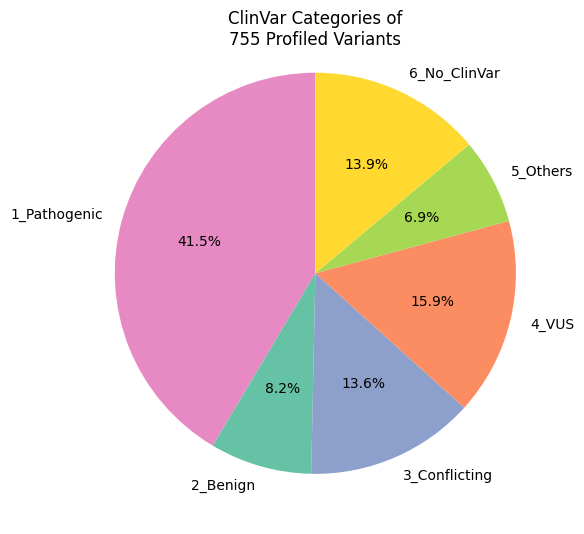

In [50]:
df = imaging_summary_clinvar.to_pandas() ## drop_nulls("clinvar_clnsig_clean").

# Count category frequencies
counts = df["clinvar_clnsig_clean"].value_counts()

# Sort categories if you want specific order
category_order = sorted(df["clinvar_clnsig_clean"].unique())
counts = counts.reindex([cat for cat in category_order if cat in counts.index])

clinvar_palette = sns.color_palette("Set2")
clinvar_palette[3], clinvar_palette[0] = clinvar_palette[0], clinvar_palette[3]
clinvar_palette_old = sns.color_palette("Set2")
clinvar_palette_old[0], clinvar_palette_old[1], clinvar_palette_old[3] = clinvar_palette_old[3], clinvar_palette_old[0], clinvar_palette_old[1]

# Plot pie chart
fig, ax = plt.subplots(figsize=(6, 7))
ax.pie(
    counts,
    labels=counts.index,
    autopct='%1.1f%%',
    startangle=90,
    colors=clinvar_palette_old
)
ax.set_title(f"ClinVar Categories of\n{df.shape[0]} Profiled Variants",y=.94)
plt.tight_layout()
plt.show()

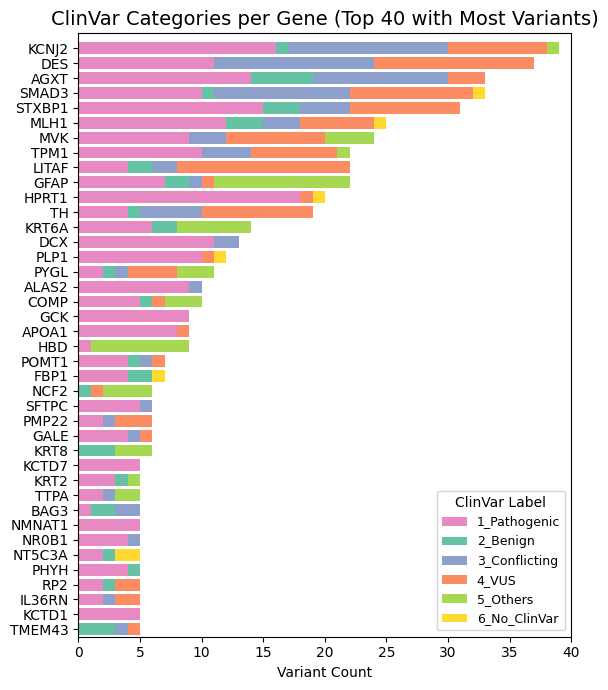

In [51]:
# 2. Count per (gene, category)
top_num = 40
counts = (
    df.groupby(["symbol", "clinvar_clnsig_clean"])
    .size()
    .reset_index(name="count")
)
# 3. Pivot
pivot = counts.pivot(index="symbol", columns="clinvar_clnsig_clean", values="count").fillna(0)

# Add total count column and sort by it (descending)
pivot["total_count"] = pivot.sum(axis=1)
pivot = pivot.sort_values("total_count", ascending=False).head(top_num)
pivot = pivot.drop(columns=["total_count"])

# 4. Ensure category order
for cat in category_order:
    if cat not in pivot.columns:
        pivot[cat] = 0
pivot = pivot[category_order]

# 5. Plotting
fig, ax = plt.subplots(figsize=(6, 7))
# Get Set2 colors
bottom = None
for cat, color in zip(category_order, clinvar_palette_old):
    ax.barh(pivot.index, pivot[cat], left=bottom, label=cat, color=color)
    bottom = pivot[cat] if bottom is None else bottom + pivot[cat]
# Axis formatting
ax.set_xlabel("Variant Count")
ax.set_xlim(None, 40)
ax.set_ylim(-1, pivot.shape[0] - .5)  # Tighten y-axis to remove top/bottom gaps
ax.set_title(f"ClinVar Categories per Gene (Top {top_num} with Most Variants)", fontsize=14)
ax.invert_yaxis()
ax.legend(title="ClinVar Label", fontsize=9, title_fontsize=10, loc="lower right")
plt.tight_layout()
plt.show()

In [54]:
def plot_gene_level_summary(total_allele_hit_sum_df, cell_change, auroc_thres):
    # 1. Fill nulls with 0
    total_allele_hit_sum_df["len_hits"] = total_allele_hit_sum_df["len_hits"].fillna(0).astype(int)
    # 2. Compute percentage of hits
    total_allele_hit_sum_df["pct_hits"] = total_allele_hit_sum_df["len_hits"] / total_allele_hit_sum_df["len"] * 100
    # 3. Sort by percentage descending
    total_allele_hit_sum_df = total_allele_hit_sum_df.sort_values(by=["len","pct_hits"], ascending=True).reset_index(drop=True)
    
    y = range(len(total_allele_hit_sum_df))
    n_genes = len(y)

    # 4. Dynamically scale figure size
    bar_width = 0.4
    fig_height = max(6, min(n_genes * 0.3, 25))  # cap size for huge plots
    fig_width = 8
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    # Plot bars
    ax.barh(y, total_allele_hit_sum_df["len"], color="skyblue", label="# Variants")
    ax.barh(y, total_allele_hit_sum_df["len_hits"], color="tomato", label="# of Hits")

    # Annotate percentage
    for i, pct in enumerate(total_allele_hit_sum_df["pct_hits"]):
        ax.text(
            total_allele_hit_sum_df.loc[i, "len"] + 0.5,
            i,
            f"{pct:.1f}%",
            ha="left",
            va="center",
            fontsize=10 if n_genes > 20 else 11,
            rotation=0,
        )
    # Axis formatting
    ax.set_yticks(y)
    ax.set_yticklabels(
        total_allele_hit_sum_df["by"],
        fontsize=10 if n_genes > 20 else 11,
    )
    ax.set_xlabel("Count", fontsize=11)
    ax.set_title(
        f"Altered {cell_change.upper()} Hits per Gene (AUROC thres: {auroc_thres})",
        fontsize=13,
    )
    ax.set_xlim(0, total_allele_hit_sum_df["len"].max() * 1.1)
    ax.set_ylim(-1, len(y) + .3)
    ax.legend(fontsize=11, loc="lower right")
    # Improve spacing
    plt.tight_layout()
    plt.show()
    return total_allele_hit_sum_df

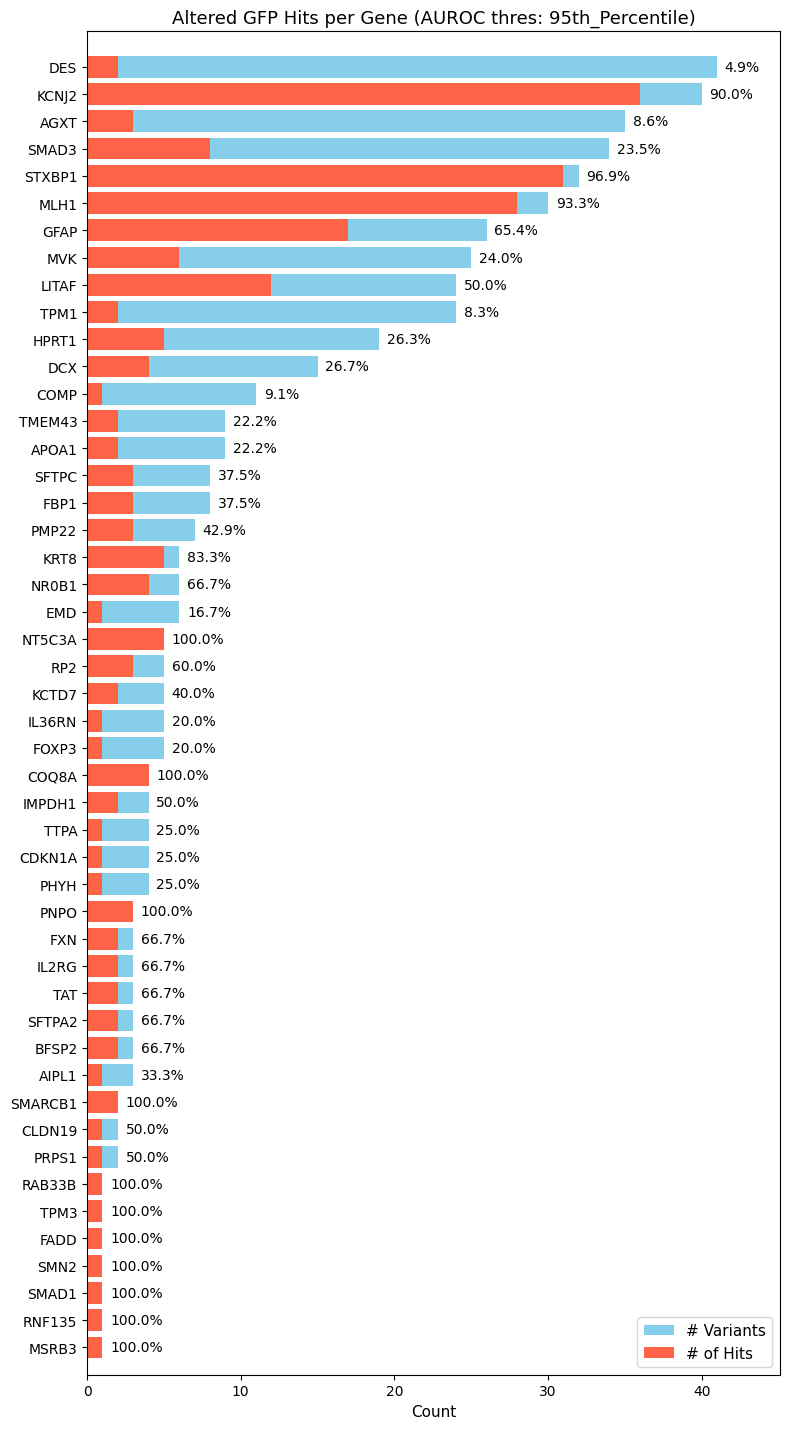

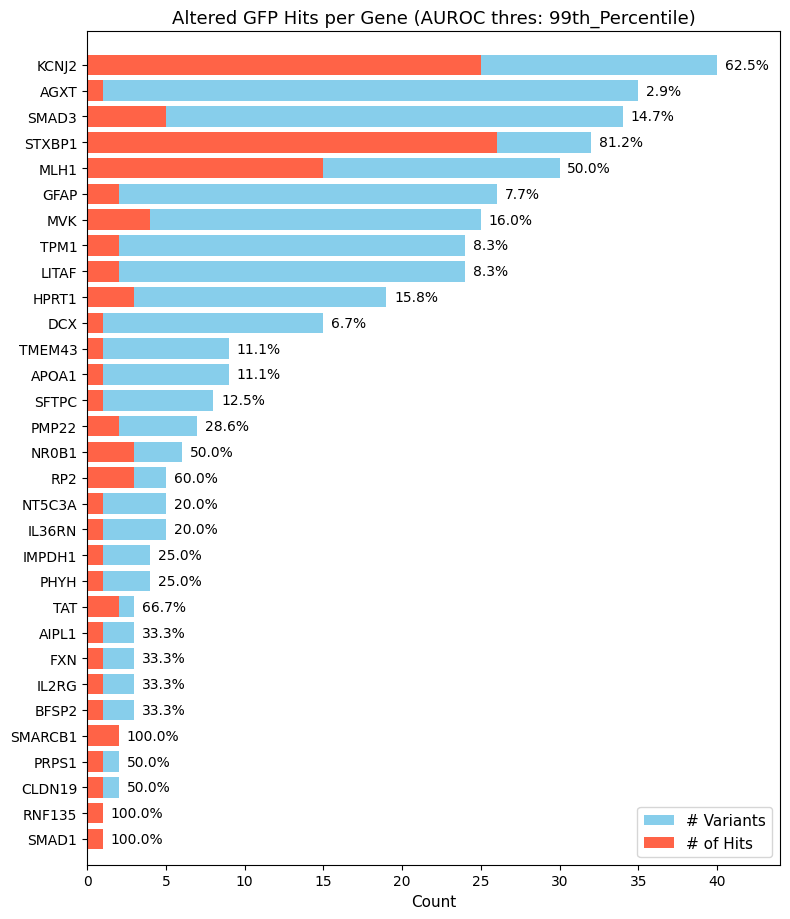

In [56]:
total_allele_hit_sum_df = auroc_summary.group_by("Gene").len().sort(by="len", descending=True).join(
    auroc_summary.filter(pl.col(f"Altered_95th_perc_GFP")==1).with_columns(
        pl.col("gene_allele").str.split("_").list.get(0).alias("Gene")
    ).group_by(by="Gene").len().sort(by="len", descending=True),
    left_on="Gene",
    right_on="by",
    suffix="_hits", how="left"
).drop_nulls(subset="len_hits").rename({"Gene":"by"})
total_allele_hit_sum_df = plot_gene_level_summary(total_allele_hit_sum_df.to_pandas(), "GFP", f"{95}th_Percentile")

total_allele_hit_sum_df = auroc_summary.group_by("Gene").len().sort(by="len", descending=True).join(
    auroc_summary.filter(pl.col(f"Altered_99th_perc_GFP")==1).with_columns(
        pl.col("gene_allele").str.split("_").list.get(0).alias("Gene")
    ).group_by(by="Gene").len().sort(by="len", descending=True),
    left_on="Gene",
    right_on="by",
    suffix="_hits", how="left"
).drop_nulls(subset="len_hits").rename({"Gene":"by"})
total_allele_hit_sum_df = plot_gene_level_summary(total_allele_hit_sum_df.to_pandas(), "GFP", f"{99}th_Percentile")

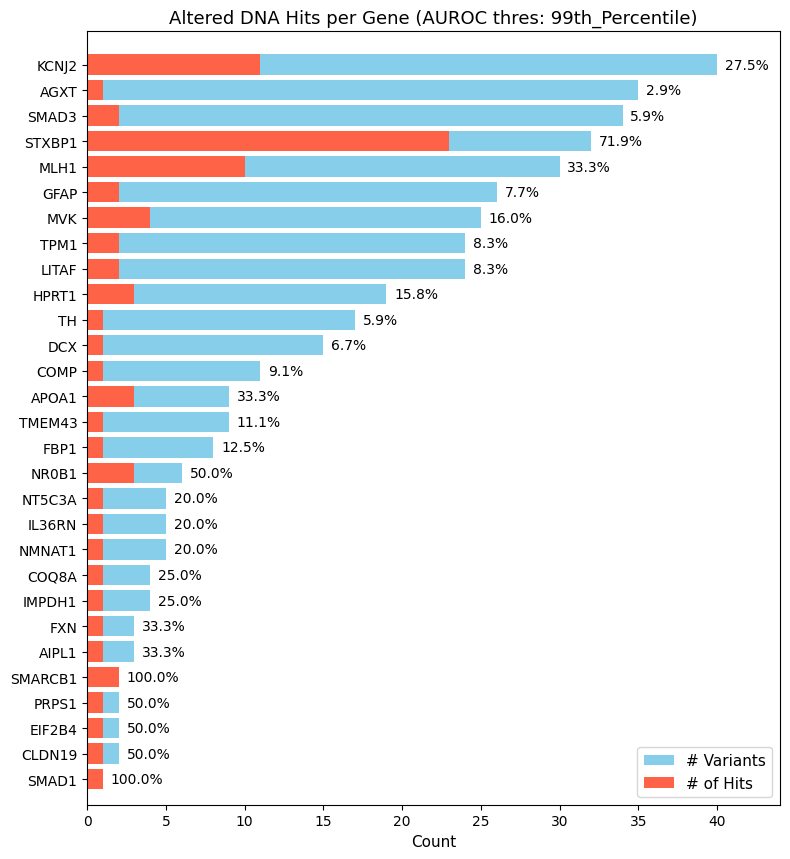

In [57]:
total_allele_hit_sum_df = auroc_summary.group_by("Gene").len().sort(by="len", descending=True).join(
    auroc_summary.filter(pl.col(f"Altered_99th_perc_DNA")==1).with_columns(
        pl.col("gene_allele").str.split("_").list.get(0).alias("Gene")
    ).group_by(by="Gene").len().sort(by="len", descending=True),
    left_on="Gene",
    right_on="by",
    suffix="_hits", how="left"
).drop_nulls(subset="len_hits").rename({"Gene":"by"})
total_allele_hit_sum_df = plot_gene_level_summary(total_allele_hit_sum_df.to_pandas(), "DNA", f"{99}th_Percentile")

In [55]:
# merge scores with metadata
scores = pl.read_csv(f"{img_outputs}/auroc_zscore_b7-8.csv").filter(
    pl.col("Classifier_type") == "localization"
).select(["allele_0", "auroc_zscore_b7", "auroc_zscore_b8"]).with_columns(
    pl.mean_horizontal(pl.col("auroc_zscore_b7"), pl.col("auroc_zscore_b8")).alias("mean_auroc_zscore")
)

b7 = pl.read_csv(f"{img_outputs}/2024_01_23_Batch_7/profiles_tcdropped_filtered_var_mad_outlier_featselect/metrics_summary.csv").filter(
    pl.col("Classifier_type") == "localization"
).select(["allele_0", "Batch", "AUROC_mean"])

b8 = pl.read_csv(f"{img_outputs}/2024_02_06_Batch_8/profiles_tcdropped_filtered_var_mad_outlier_featselect/metrics_summary.csv").filter(
    pl.col("Classifier_type") == "localization"
).select(["allele_0", "Batch", "AUROC_mean"])

auroc = pl.concat([b7, b8]).pivot(
    index="allele_0",
    on="Batch",
    values="AUROC_mean"
).rename({
    "B7": "auroc_b7",
    "B8": "auroc_b8"
})

auroc = auroc.with_columns(
    pl.mean_horizontal(pl.col("auroc_b7"), pl.col("auroc_b8")).alias("mean_auroc")
)

scores = scores.join(auroc, on="allele_0")
scores = scores.join(metadata, on="allele_0").drop("mut_id").unique()

scores.write_csv(f"{img_outputs}/annotated_perturbation_scores.csv")
scores.write_csv(f"{integrative_inputs}/misloc_scores.csv")
scores = scores.filter(pl.col("clinvar_clnsig_clean") != "5_Others")

From the plots below, we see that it's likely better to combine the AUROC across batches than the z-score.

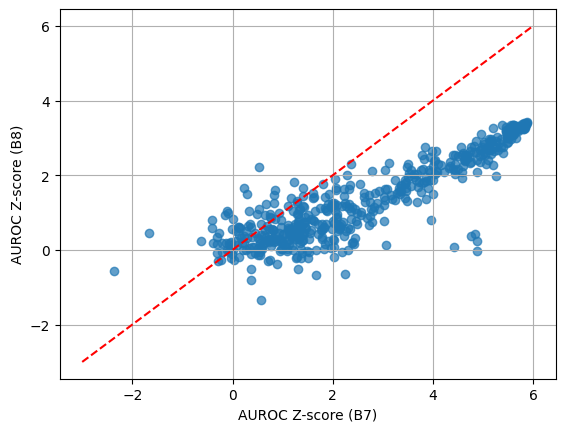

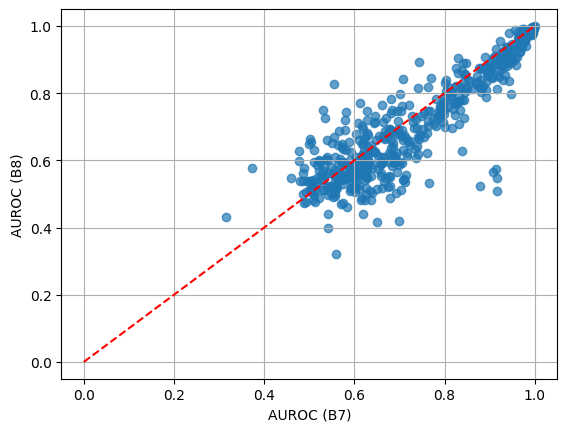

In [43]:
plt.scatter(scores['auroc_zscore_b7'], scores['auroc_zscore_b8'], alpha=0.7)
plt.plot([-3, 6], [-3, 6], color='red', linestyle='--', linewidth=1.5)
plt.ylabel('AUROC Z-score (B8)')
plt.xlabel('AUROC Z-score (B7)')
plt.grid(True)
plt.show()

plt.scatter(auroc['auroc_b7'], auroc['auroc_b8'], alpha=0.7)
plt.plot([0, 1], [0, 1], color='red', linestyle='--', linewidth=1.5)
plt.ylabel('AUROC (B8)')
plt.xlabel('AUROC (B7)')
plt.grid(True)
plt.show()

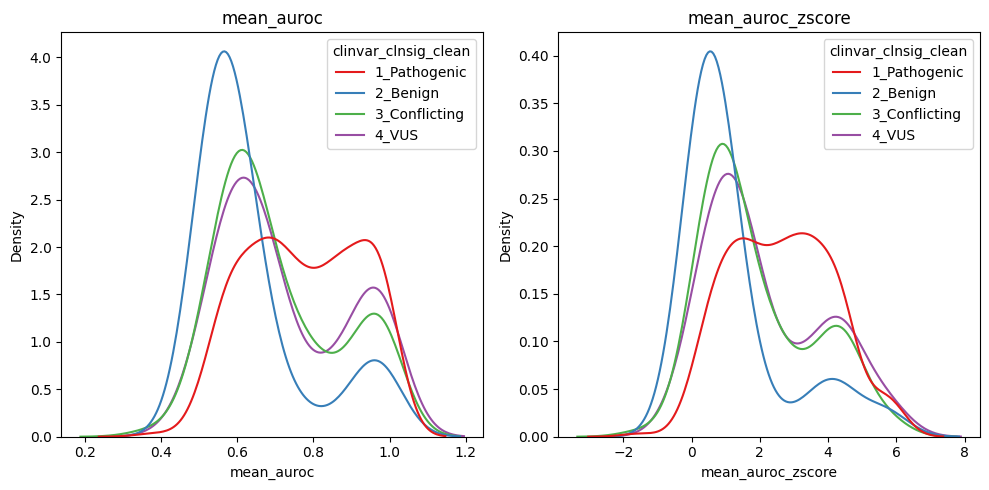

In [48]:
# Define variables to plot
variables = ["mean_auroc", "mean_auroc_zscore"]
num_vars = len(variables)

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5))
hue_order = sorted(scores["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=scores,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        ax=ax,
        palette="Set1",
        common_norm=False
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

(70, 14)
(254, 14)
(106, 14)
(109, 14)


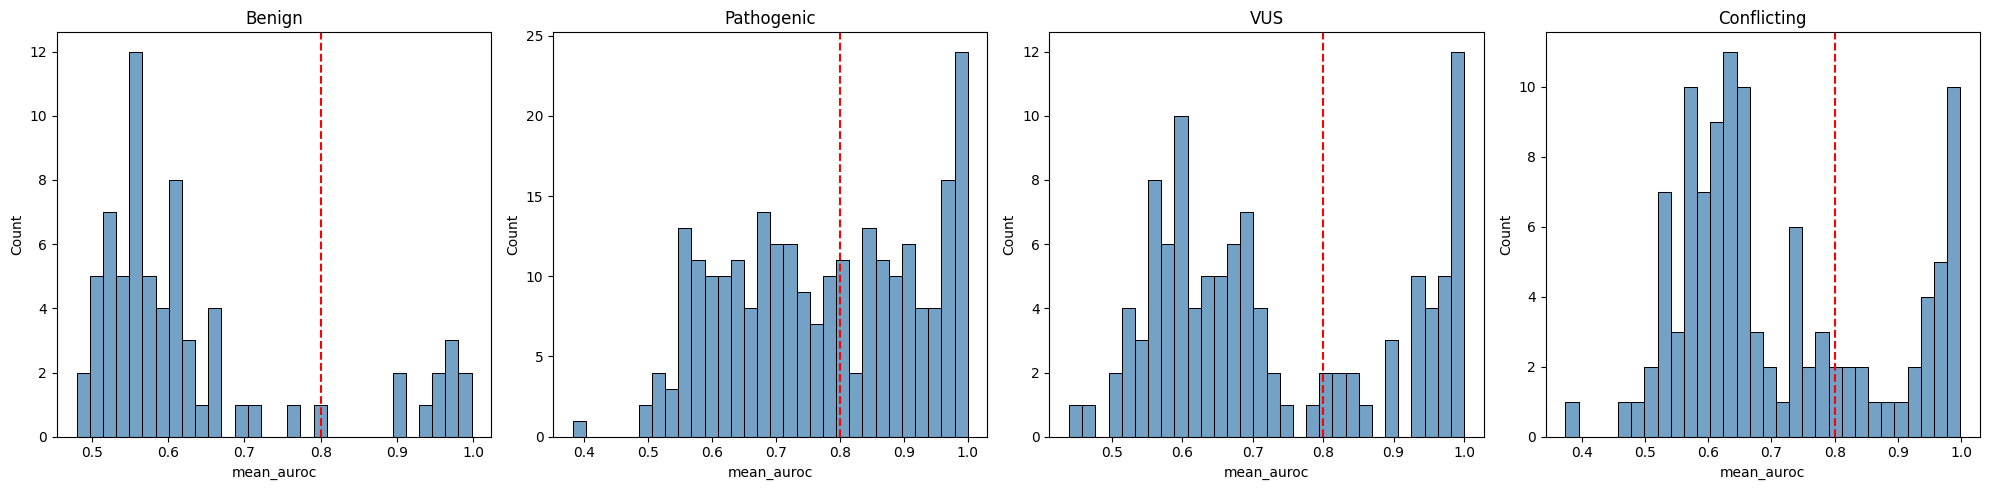

With this threshold, we classify 36 VUS and 30 conflicting alleles as pathogenic.
This threshold classifies 0.14285714285714285% of benign variants as pathogenic


In [51]:
plot_var = "mean_auroc"
thresh = 0.8

benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")
print(benign_scores.shape)

path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic")
print(path_scores.shape)

vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS")
print(vus_scores.shape)

conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting")
print(conf_scores.shape)

# Setup subplots
fig, axs = plt.subplots(1, 4, figsize=(20, 5))
plot_data = [
    ("Benign", benign_scores, axs[0]),
    ("Pathogenic", path_scores, axs[1]),
    ("VUS", vus_scores, axs[2]),
    ("Conflicting", conf_scores, axs[3]),
]

# Plot each group
for title, data, ax in plot_data:
    sns.histplot(data=data, x=plot_var, bins=30, color="steelblue", kde=False, ax=ax)
    ax.axvline(thresh, color="red", linestyle="--", linewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel(plot_var)
    ax.set_ylabel("Count")
    ax.grid(False)

plt.tight_layout()
plt.show()

benign_misclass = benign_scores.filter(pl.col(plot_var) > thresh).shape[0]
benign_total = benign_scores.shape[0]
print(f"With this threshold, we classify {vus_scores.filter(pl.col(plot_var) > thresh).shape[0]} VUS and {conf_scores.filter(pl.col(plot_var) > thresh).shape[0]} conflicting alleles as pathogenic.")
print(f"This threshold classifies {benign_misclass/benign_total}% of benign variants as pathogenic")

(539, 14)
(440, 14)


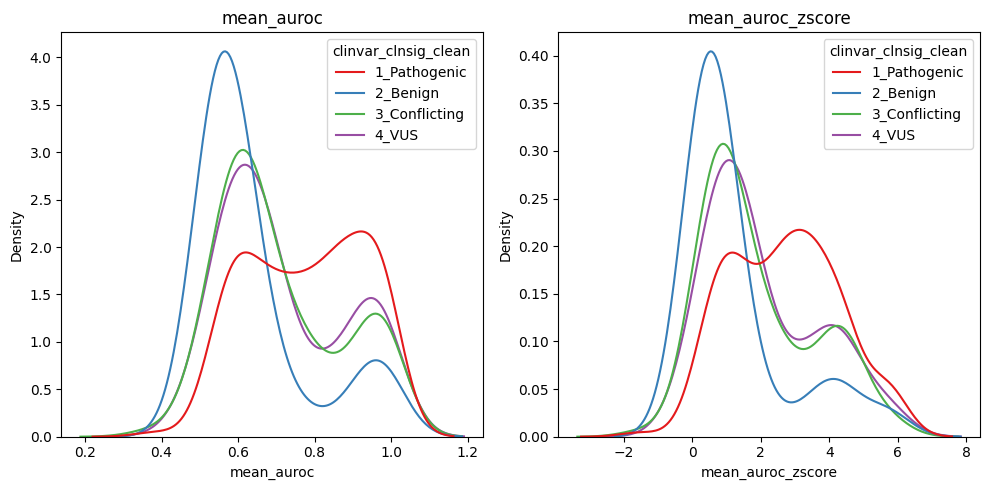

In [49]:
# Define variables to plot
variables = ["mean_auroc", "mean_auroc_zscore"]
num_vars = len(variables)

print(scores.shape)
scores_filt = scores.filter(pl.col("StarStatus") >= 1)
print(scores_filt.shape)

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, num_vars, figsize=(num_vars*5, 5))
hue_order = sorted(scores_filt["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=scores_filt,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        ax=ax,
        palette="Set1",
        common_norm=False
    )
    ax.set_title(var)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from scipy import stats
from scipy.optimize import minimize_scalar
import warnings
warnings.filterwarnings('ignore')

# Set style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

class DistributionAnalyzer:
    """
    Class to analyze and compare distributions using Gaussian Mixture Models
    """
    
    def __init__(self, data_dict):
        """
        Initialize with data dictionary where keys are category names and values are arrays
        """
        self.data_dict = data_dict
        self.fitted_models = {}
        self.model_info = {}
        
    def fit_gmm(self, category, n_components_range=(1, 5), criterion='bic'):
        """
        Fit Gaussian Mixture Model with optimal number of components
        """
        data = self.data_dict[category].reshape(-1, 1)
        
        # Test different numbers of components
        scores = []
        models = []
        
        for n_comp in range(n_components_range[0], n_components_range[1] + 1):
            gmm = GaussianMixture(n_components=n_comp, random_state=42)
            gmm.fit(data)
            
            if criterion == 'bic':
                score = gmm.bic(data)
            else:  # aic
                score = gmm.aic(data)
                
            scores.append(score)
            models.append(gmm)
        
        # Select best model (lowest BIC/AIC)
        best_idx = np.argmin(scores)
        best_model = models[best_idx]
        best_n_comp = best_idx + n_components_range[0]
        
        self.fitted_models[category] = best_model
        self.model_info[category] = {
            'n_components': best_n_comp,
            'score': scores[best_idx],
            'means': best_model.means_.flatten(),
            'covariances': best_model.covariances_.flatten(),
            'weights': best_model.weights_
        }
        
        return best_model
    
    def fit_all_categories(self):
        """
        Fit GMM for all categories
        """
        for category in self.data_dict.keys():
            self.fit_gmm(category)
    
    def plot_distributions_with_gmm(self, figsize=(15, 10)):
        """
        Plot original distributions with fitted GMM overlays
        """
        n_categories = len(self.data_dict)
        fig, axes = plt.subplots(2, 2, figsize=figsize)
        axes = axes.flatten()
        
        colors = ['red', 'blue', 'green', 'purple']
        
        for i, (category, data) in enumerate(self.data_dict.items()):
            ax = axes[i]
            
            # Plot histogram
            ax.hist(data, bins=50, density=True, alpha=0.6, 
                   color=colors[i], label=f'{category} (Data)')
            
            # Plot fitted GMM
            if category in self.fitted_models:
                x_range = np.linspace(data.min(), data.max(), 1000)
                gmm = self.fitted_models[category]
                
                # Overall GMM
                log_prob = gmm.score_samples(x_range.reshape(-1, 1))
                prob = np.exp(log_prob)
                ax.plot(x_range, prob, color='black', linewidth=2, 
                       label=f'GMM ({self.model_info[category]["n_components"]} components)')
                
                # Individual components
                for j in range(gmm.n_components):
                    component_prob = gmm.weights_[j] * stats.norm.pdf(
                        x_range, 
                        gmm.means_[j, 0], 
                        np.sqrt(gmm.covariances_[j, 0, 0])
                    )
                    ax.plot(x_range, component_prob, '--', alpha=0.7,
                           label=f'Component {j+1}')
            
            ax.set_title(f'{category}')
            ax.set_xlabel('zscore_log2')
            ax.set_ylabel('Density')
            ax.legend()
            ax.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    def compare_with_null(self, null_category='2_Benign'):
        """
        Compare all distributions with the null distribution (2_Benign)
        """
        if null_category not in self.fitted_models:
            raise ValueError(f"Null category {null_category} not found in fitted models")
        
        null_model = self.fitted_models[null_category]
        results = {}
        
        for category, model in self.fitted_models.items():
            if category == null_category:
                continue
                
            # Calculate KL divergence
            kl_div = self._calculate_kl_divergence(null_model, model)
            
            # Identify extra peaks
            extra_peaks = self._identify_extra_peaks(null_model, model, category)
            
            results[category] = {
                'kl_divergence': kl_div,
                'extra_peaks': extra_peaks,
                'n_components': self.model_info[category]['n_components'],
                'null_n_components': self.model_info[null_category]['n_components']
            }
        
        return results
    
    def _calculate_kl_divergence(self, model1, model2, n_samples=10000):
        """
        Calculate KL divergence between two GMM models
        """
        # Sample points for comparison
        data_range = np.linspace(-25, 5, n_samples).reshape(-1, 1)
        
        # Get log probabilities
        log_prob1 = model1.score_samples(data_range)
        log_prob2 = model2.score_samples(data_range)
        
        # Convert to probabilities and normalize
        prob1 = np.exp(log_prob1)
        prob2 = np.exp(log_prob2)
        
        prob1 = prob1 / np.sum(prob1)
        prob2 = prob2 / np.sum(prob2)
        
        # Calculate KL divergence (avoid log(0))
        epsilon = 1e-10
        kl_div = np.sum(prob2 * np.log((prob2 + epsilon) / (prob1 + epsilon)))
        
        return kl_div
    
    def _identify_extra_peaks(self, null_model, target_model, category):
        """
        Identify extra peaks in target distribution compared to null
        """
        null_means = null_model.means_.flatten()
        target_means = target_model.means_.flatten()
        target_weights = target_model.weights_
        
        # Find target peaks that are far from null peaks
        extra_peaks = []
        threshold_distance = 2.0  # Adjust based on your data scale
        
        for i, (mean, weight) in enumerate(zip(target_means, target_weights)):
            # Check if this peak is far from all null peaks
            min_distance = np.min(np.abs(mean - null_means))
            
            if min_distance > threshold_distance and weight > 0.1:  # Significant weight
                extra_peaks.append({
                    'mean': mean,
                    'weight': weight,
                    'component': i,
                    'distance_from_null': min_distance
                })
        
        return extra_peaks
    
    def find_optimal_threshold(self, null_category='2_Benign', target_category='1_Pathogenic'):
        """
        Find optimal threshold to separate null from target distribution
        """
        null_data = self.data_dict[null_category]
        target_data = self.data_dict[target_category]
        
        # Define range for threshold search
        min_val = min(null_data.min(), target_data.min())
        max_val = max(null_data.max(), target_data.max())
        
        def objective(threshold):
            # Calculate misclassification rate
            null_misclass = np.sum(null_data < threshold) / len(null_data)
            target_misclass = np.sum(target_data >= threshold) / len(target_data)
            return null_misclass + target_misclass
        
        # Find optimal threshold
        result = minimize_scalar(objective, bounds=(min_val, max_val), method='bounded')
        optimal_threshold = result.x
        
        # Calculate performance metrics
        null_correct = np.sum(null_data >= optimal_threshold) / len(null_data)
        target_correct = np.sum(target_data < optimal_threshold) / len(target_data)
        
        return {
            'threshold': optimal_threshold,
            'null_accuracy': null_correct,
            'target_accuracy': target_correct,
            'overall_accuracy': (null_correct + target_correct) / 2
        }
    
    def plot_comparison_with_threshold(self, null_category='2_Benign', 
                                     target_category='1_Pathogenic', figsize=(12, 8)):
        """
        Plot comparison between null and target with optimal threshold
        """
        threshold_info = self.find_optimal_threshold(null_category, target_category)
        threshold = threshold_info['threshold']
        
        fig, (ax1, ax2) = plt.subplots(2, 1, figsize=figsize)
        
        # Plot 1: Overlapping distributions with threshold
        null_data = self.data_dict[null_category]
        target_data = self.data_dict[target_category]
        
        ax1.hist(null_data, bins=50, density=True, alpha=0.6, 
                color='blue', label=f'{null_category} (NULL)')
        ax1.hist(target_data, bins=50, density=True, alpha=0.6, 
                color='red', label=f'{target_category}')
        
        # Add fitted GMM curves
        x_range = np.linspace(min(null_data.min(), target_data.min()), 
                             max(null_data.max(), target_data.max()), 1000)
        
        null_prob = np.exp(self.fitted_models[null_category].score_samples(x_range.reshape(-1, 1)))
        target_prob = np.exp(self.fitted_models[target_category].score_samples(x_range.reshape(-1, 1)))
        
        ax1.plot(x_range, null_prob, color='blue', linewidth=2, linestyle='--')
        ax1.plot(x_range, target_prob, color='red', linewidth=2, linestyle='--')
        
        # Add threshold line
        ax1.axvline(threshold, color='black', linestyle='-', linewidth=2, 
                   label=f'Optimal Threshold: {threshold:.2f}')
        
        ax1.set_xlabel('zscore_log2')
        ax1.set_ylabel('Density')
        ax1.set_title(f'Distribution Comparison: {null_category} vs {target_category}')
        ax1.legend()
        ax1.grid(True, alpha=0.3)
        
        # Plot 2: Difference in distributions
        diff = target_prob - null_prob
        ax2.plot(x_range, diff, color='purple', linewidth=2)
        ax2.axhline(0, color='black', linestyle='--', alpha=0.5)
        ax2.axvline(threshold, color='black', linestyle='-', linewidth=2, alpha=0.7)
        ax2.fill_between(x_range, diff, 0, where=(diff > 0), alpha=0.3, color='red')
        ax2.fill_between(x_range, diff, 0, where=(diff < 0), alpha=0.3, color='blue')
        
        ax2.set_xlabel('zscore_log2')
        ax2.set_ylabel('Density Difference')
        ax2.set_title(f'Difference: {target_category} - {null_category}')
        ax2.grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
        
        # Print results
        print(f\"\\nThreshold Analysis Results:\")
        print(f\"Optimal Threshold: {threshold:.3f}\")
        print(f\"{null_category} Accuracy: {threshold_info['null_accuracy']:.3f}\")
        print(f\"{target_category} Accuracy: {threshold_info['target_accuracy']:.3f}\")
        print(f"Overall Accuracy: {threshold_info['overall_accuracy']:.3f}")
    
    def generate_summary_report(self):
        \"\"\"
        Generate a comprehensive summary report
        \"\"\"
        print(\"=== GAUSSIAN MIXTURE MODEL ANALYSIS REPORT ===\")
        print(\"\\n1. MODEL FITTING RESULTS:\")
        
        for category, info in self.model_info.items():
            print(f"\n{category}:")
            print(f\"  - Optimal components: {info['n_components']}\")
            print(f\"  - BIC score: {info['score']:.2f}\")
            print(f\"  - Component means: {info['means']}\")
            print(f\"  - Component weights: {info['weights']}\")
        
        print(\"\\n2. COMPARISON WITH NULL (2_Benign):\")
        comparison_results = self.compare_with_null()
        
        for category, results in comparison_results.items():
            print(f\"\\n{category}:\")
            print(f\"  - KL Divergence from null: {results['kl_divergence']:.4f}\")
            print(f\"  - Number of extra peaks: {len(results['extra_peaks'])}\")
            
            if results['extra_peaks']:
                for i, peak in enumerate(results['extra_peaks']):
                    print(f\"    Peak {i+1}: mean={peak['mean']:.2f}, weight={peak['weight']:.3f}\")

# Example usage (replace with your actual data):
# Assuming you have your data loaded in a dictionary format
# data_dict = {
#     '1_Pathogenic': pathogenic_zscore_data,
#     '2_Benign': benign_zscore_data, 
#     '3_Conflicting': conflicting_zscore_data,
#     '4_VUS': vus_zscore_data
# }

# If you need to load data from your existing variables, do something like:
# data_dict = {
#     '1_Pathogenic': df[df['category'] == '1_Pathogenic']['zscore_log2'].values,
#     '2_Benign': df[df['category'] == '2_Benign']['zscore_log2'].values,
#     '3_Conflicting': df[df['category'] == '3_Conflicting']['zscore_log2'].values,
#     '4_VUS': df[df['category'] == '4_VUS']['zscore_log2'].values
# }

# Example with synthetic data (replace with your actual data):
np.random.seed(42)
data_dict = {
    '1_Pathogenic': np.concatenate([
        np.random.normal(-8, 2, 1000),  # Main peak
        np.random.normal(-15, 1.5, 300)  # Extra peak
    ]),
    '2_Benign': np.random.normal(-5, 3, 1500),  # NULL distribution
    '3_Conflicting': np.concatenate([
        np.random.normal(-5, 3, 800),   # Similar to benign
        np.random.normal(-12, 2, 400)   # Extra component
    ]),
    '4_VUS': np.concatenate([
        np.random.normal(-6, 3.5, 1000),  # Main peak
        np.random.normal(-2, 1, 200)      # Right tail
    ])
}

# Initialize analyzer
analyzer = DistributionAnalyzer(data_dict)

# Fit GMM models for all categories
print(\"Fitting Gaussian Mixture Models...\")
analyzer.fit_all_categories()

# Plot distributions with GMM fits
print(\"\\nPlotting distributions with GMM overlays...\")
analyzer.plot_distributions_with_gmm()

# Generate comprehensive report
analyzer.generate_summary_report()

# Compare specific categories with threshold analysis
print(\"\\n=== THRESHOLD ANALYSIS ===\")
categories_to_compare = ['1_Pathogenic', '3_Conflicting', '4_VUS']

for category in categories_to_compare:
    print(f\"\\nAnalyzing {category} vs 2_Benign:\")
    analyzer.plot_comparison_with_threshold('2_Benign', category)